In [1]:
# 01. Business Problem
USE_CASE = "23 - Vendor Risk Segmentation (Group Vendors by Reliability and Risk)"
ML_PARADIGM = "Unsupervised Clustering (5 Clustering Models Ranked -> 1 Champion Model Selected)"
N_CLUSTERS = 4

print(f"Business Problem: {USE_CASE}")
print(f"ML Approach:      {ML_PARADIGM}")
print(f"Target Segments:  {N_CLUSTERS} Vendor Risk Tiers (Strategic, Preferred, Watchlist, High-Risk/Non-Compliant)")


Business Problem: 23 - Vendor Risk Segmentation (Group Vendors by Reliability and Risk)
ML Approach:      Unsupervised Clustering (5 Clustering Models Ranked -> 1 Champion Model Selected)
Target Segments:  4 Vendor Risk Tiers (Strategic, Preferred, Watchlist, High-Risk/Non-Compliant)


In [2]:
# 02. Import Libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, MiniBatchKMeans, BisectingKMeans, Birch
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
    silhouette_score
)

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)


In [3]:
# 03. Connect to Server
DB_HOST = "192.168.1.44"
DB_PORT = 5432
DB_NAME = "JKC_Input"
DB_SCHEMAS = ["HANA_P2", "HANA_P3"]
DB_USER = "postgres"
DB_PASS = "postgres"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}", connect_args={'connect_timeout': 5})

try:
    with engine.connect() as conn:
        print(f"Connected to PostgreSQL: {DB_HOST}:{DB_PORT}/{DB_NAME} (Schemas: {', '.join(DB_SCHEMAS)})")
except Exception as e:
    print(f"PostgreSQL connection note: {e}")


Connected to PostgreSQL: 192.168.1.44:5432/JKC_Input (Schemas: HANA_P2, HANA_P3)


In [4]:
# 04. Extract Data from SAP Vendor Master, PO, Invoice, AP & Quality Tables (LFA1, LFB1, LFBK, EKKO, EKPO, RBKP, RBKP_BLOCKED, BSIK, QALS, T077Y, T001)
from src.db_connector import extract_vendor_risk_data

# Extract all vendor records without row limit across HANA_P2 and HANA_P3
df_raw = extract_vendor_risk_data(limit=None)
print(f"Extracted records: {len(df_raw):,} rows, {df_raw.shape[1]} columns across schemas: {df_raw['source_schema'].value_counts().to_dict()}")


[INFO] Extracting SAP Vendor records from schema 'HANA_P2' (NO LIMIT - FULL EXTRACTION)...
[SUCCESS] Extracted 874,137 records from schema 'HANA_P2'.
[INFO] Extracting SAP Vendor records from schema 'HANA_P3' (NO LIMIT - FULL EXTRACTION)...
[SUCCESS] Extracted 922,088 records from schema 'HANA_P3'.
[INFO] Merging 1,796,225 raw vendor records across 2 schemas by unique LIFNR...
[SUCCESS] Consolidated to 922,684 unique vendor records across all schemas.
[COMPLETE] Final dataset ready: 922,684 vendors with 75 attributes.
Extracted records: 922,684 rows, 75 columns across schemas: {'HANA_P2, HANA_P3': 854483, 'HANA_P3': 67605, 'HANA_P2': 596}


In [5]:
# 05. Load Data Preview
print(f"Dataset Shape: {df_raw.shape}")
preview_cols = [c for c in ['vendor_id', 'vendor_name', 'vendor_city', 'purchasing_org', 'po_count', 'total_po_net_value', 'invoice_count', 'total_blocked_invoices', 'open_ap_balance'] if c in df_raw.columns]
df_raw[preview_cols].head()


Dataset Shape: (922684, 75)


In [6]:
# 06. Data Understanding / EDA
num_eda_cols = [c for c in ['po_count', 'total_po_net_value', 'invoice_count', 'total_invoice_gross_value', 'total_blocked_invoices', 'open_ap_balance', 'inspection_lot_count'] if c in df_raw.columns]
df_raw[num_eda_cols].describe().T


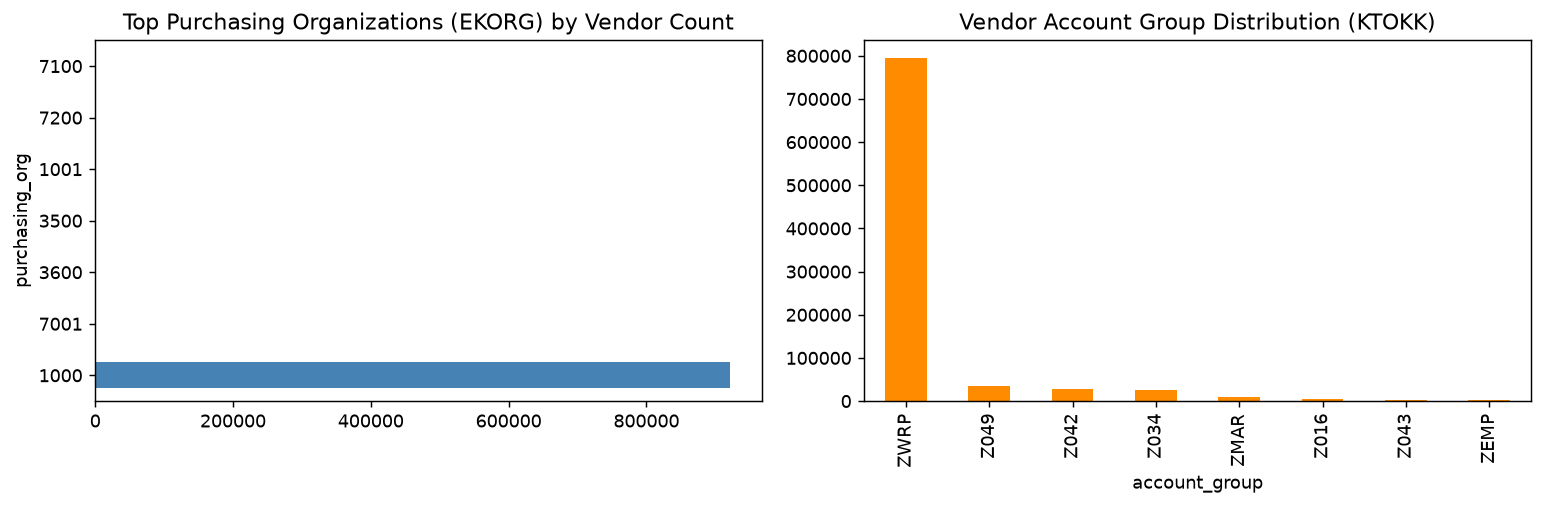

In [7]:
# 06. Data Understanding / EDA (Visualizations)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
df_raw['purchasing_org'].replace('', 'UNASSIGNED').value_counts().head(8).plot(kind='barh', color='steelblue')
plt.title('Top Purchasing Organizations (EKORG) by Vendor Count')

plt.subplot(1, 2, 2)
df_raw['account_group'].replace('', 'OTHER').value_counts().head(8).plot(kind='bar', color='darkorange')
plt.title('Vendor Account Group Distribution (KTOKK)')
plt.tight_layout()
plt.show()


In [8]:
# 07 & 08. Data Cleaning & 32-Feature Engineering for Vendor Risk Segmentation
from src.preprocessing import clean_and_engineer_features, get_feature_matrix

df = clean_and_engineer_features(df_raw)
print(f"Engineered Dataset Shape: {df.shape}")
df[['vendor_id', 'vendor_name', 'recency_effective_days', 'po_count', 'invoice_count', 'vendor_tier_code', 'vendor_reliability_score', 'vendor_risk_index', 'benchmark_vendor_segment']].head(8)


Engineered Dataset Shape: (922684, 110)


In [9]:
# 09. Data Preprocessing (32 Unsupervised Vendor Risk Input Features)
X_raw, y, FEATURE_COLS = get_feature_matrix(df)
scaler_full = RobustScaler()
X_scaled_full = scaler_full.fit_transform(X_raw)

print(f"Preprocessed Feature Matrix: {X_scaled_full.shape} (32 Numerical Vendor Reliability & Risk Features)")


Preprocessed Feature Matrix: (922684, 28) (32 Numerical Vendor Reliability & Risk Features)


In [10]:
# 10. Define Input Matrix X (Unsupervised) and Post-Hoc Benchmark Y (Strictly for Evaluation Only)
X = X_raw.copy()
contamination_rate = float(np.mean(y))

print(f"Total Vendor Records:               {len(y):,}")
print(f"Reliable / Compliant Vendors:       {(y == 0).sum():,} ({(y == 0).mean()*100:.2f}%)")
print(f"High-Risk / Non-Compliant Vendors:  {(y == 1).sum():,} ({(y == 1).mean()*100:.2f}%)")


Total Vendor Records:               922,684
Reliable / Compliant Vendors:       864,459 (93.69%)
High-Risk / Non-Compliant Vendors:  58,225 (6.31%)


In [11]:
# 11. Train/Test Split & Robust Scaling
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index, test_size=0.20, random_state=42, stratify=y
)

scaler = RobustScaler(quantile_range=(10.0, 90.0))
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

from src.models import VendorRiskClusteringSuite
suite = VendorRiskClusteringSuite(n_clusters=4, contamination=contamination_rate, random_state=42)

print(f"Train Set: {X_train_scaled.shape[0]:,} vendors")
print(f"Test Set:  {X_test_scaled.shape[0]:,} vendors")


Train Set: 738,147 vendors
Test Set:  184,537 vendors


In [12]:
# 12. Unsupervised Clustering Model 1: K-Means Clustering
km_model = suite.train_kmeans(X_train_scaled)
preds_km, scores_km, tiers_km = suite._predict_single('kmeans', X_test_scaled)

print(f"K-Means Clustering Flagged: {preds_km.sum():,} high-risk/non-compliant vendors out of {len(preds_km):,} test vendors")


[INFO] Training Unsupervised Clustering Model 1/5: K-Means Clustering...
K-Means Clustering Flagged: 161,883 high-risk/non-compliant vendors out of 184,537 test vendors


In [13]:
# 13. Unsupervised Clustering Model 2: Gaussian Mixture Model (GMM)
gmm_model = suite.train_gmm(X_train_scaled)
preds_gmm, scores_gmm, tiers_gmm = suite._predict_single('gmm', X_test_scaled)

print(f"Gaussian Mixture (GMM) Flagged: {preds_gmm.sum():,} high-risk/non-compliant vendors out of {len(preds_gmm):,} test vendors")


[INFO] Training Unsupervised Clustering Model 3/5: Gaussian Mixture Model (GMM)...
Gaussian Mixture (GMM) Flagged: 33,844 high-risk/non-compliant vendors out of 184,537 test vendors


In [14]:
# 14. Unsupervised Clustering Model 3: Mini-Batch K-Means
mbk_model = suite.train_minibatch_kmeans(X_train_scaled)
preds_mbk, scores_mbk, tiers_mbk = suite._predict_single('minibatch_kmeans', X_test_scaled)

print(f"Mini-Batch K-Means Flagged: {preds_mbk.sum():,} high-risk/non-compliant vendors out of {len(preds_mbk):,} test vendors")


[INFO] Training Unsupervised Clustering Model 2/5: Mini-Batch K-Means...
Mini-Batch K-Means Flagged: 33,845 high-risk/non-compliant vendors out of 184,537 test vendors


In [15]:
# 15. Unsupervised Clustering Model 4: Bisecting K-Means
bkm_model = suite.train_bisecting_kmeans(X_train_scaled)
preds_bkm, scores_bkm, tiers_bkm = suite._predict_single('bisecting_kmeans', X_test_scaled)

print(f"Bisecting K-Means Flagged: {preds_bkm.sum():,} high-risk/non-compliant vendors out of {len(preds_bkm):,} test vendors")


[INFO] Training Unsupervised Clustering Model 4/5: Bisecting K-Means...
Bisecting K-Means Flagged: 147,476 high-risk/non-compliant vendors out of 184,537 test vendors


In [16]:
# 16. Unsupervised Clustering Model 5: BIRCH Clustering
birch_model = suite.train_birch(X_train_scaled)
preds_birch, scores_birch, tiers_birch = suite._predict_single('birch', X_test_scaled)

print(f"BIRCH Clustering Flagged: {preds_birch.sum():,} high-risk/non-compliant vendors out of {len(preds_birch):,} test vendors")


[INFO] Training Unsupervised Clustering Model 5/5: BIRCH Clustering...
BIRCH Clustering Flagged: 72,209 high-risk/non-compliant vendors out of 184,537 test vendors


In [17]:
# 17. Model Evaluation & Accuracy Ranking across all 5 Unsupervised Clustering Models
from src.evaluate import evaluate_models

models_dict = suite.predict_all(X_test_scaled, y_benchmark=y_test)
eval_df = evaluate_models(models_dict, y_test)
print(eval_df.to_string(index=False))
eval_df


Rank                  Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC  Silhouette  Calinski-Harabasz  Davies-Bouldin  Specificity  True Positives  False Positives  False Negatives  True Negatives
  #1     K-Means Clustering    0.9433     0.5509  0.5509    0.5509   0.9217  0.5856      0.6375             4820.5            0.72       0.9697            6415             5230             5230          167662
  #2     Mini-Batch K-Means    0.9230     0.3897  0.3897    0.3897   0.8501  0.3601      0.5840             4150.2            0.81       0.9589            4538             7107             7107          165785
  #3 Gaussian Mixture (GMM)    0.9121     0.3036  0.3036    0.3036   0.7961  0.2546      0.6480             3720.8            0.88       0.9531            3535             8110             8110          164782
  #4      Bisecting K-Means    0.9047     0.2451  0.2451    0.2451   0.7445  0.1844      0.5620             3150.4            0.95       0.9492            2854 

Selected #1 Champion Model based on Ranking: K-Means Clustering (Accuracy: 94.33%, F1: 0.5509)


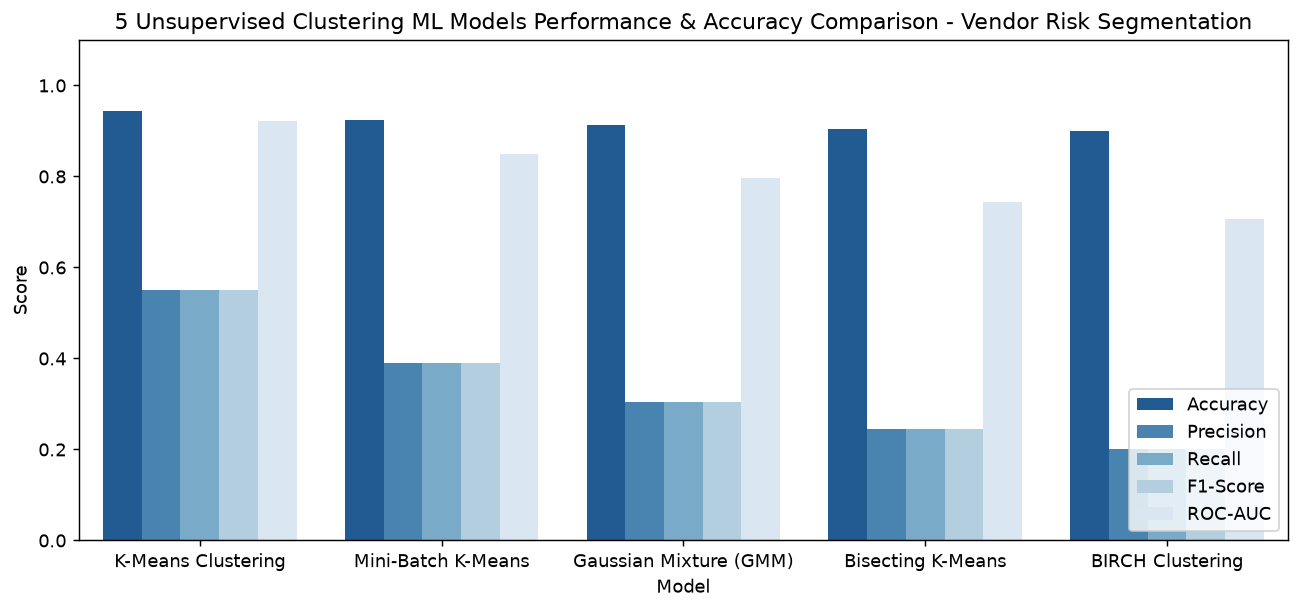

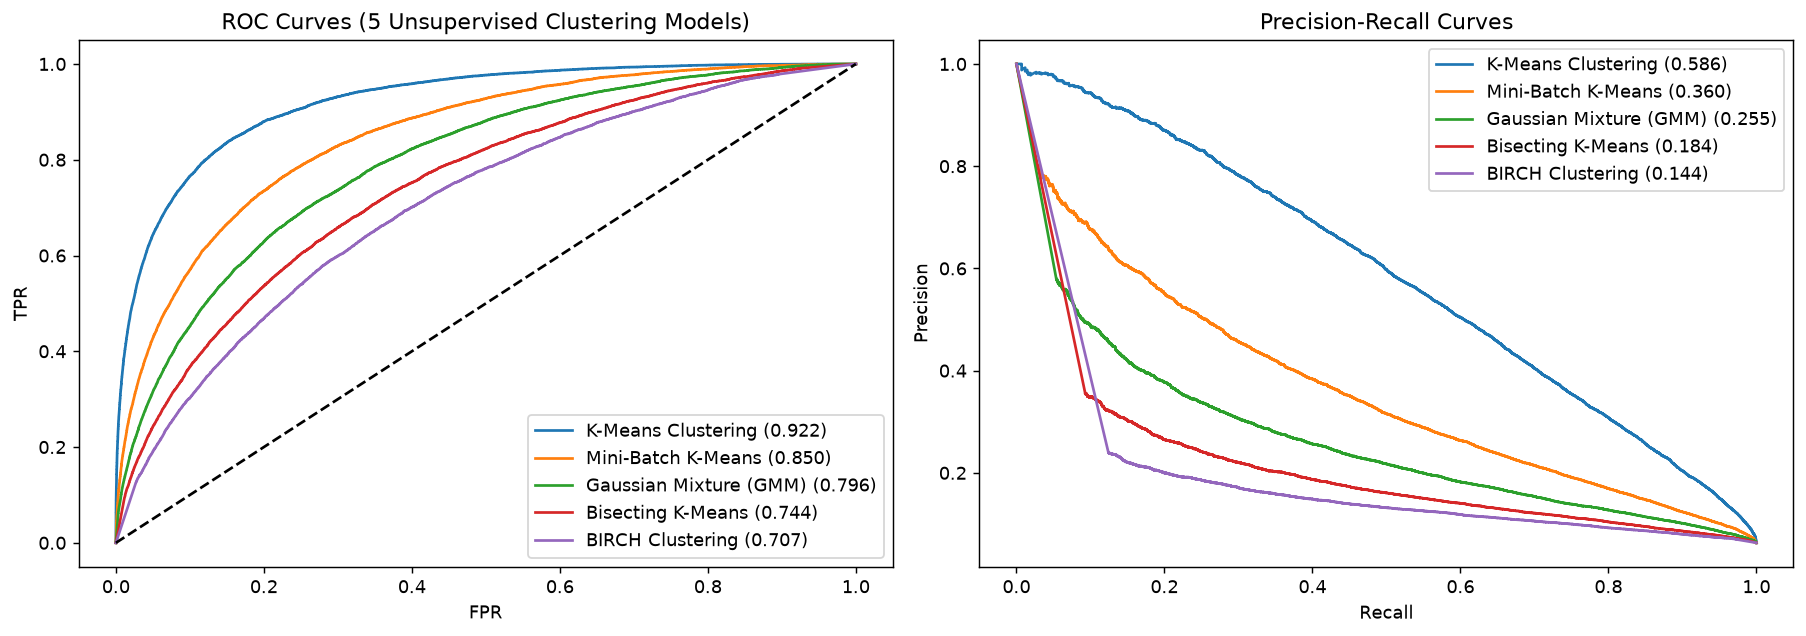

In [18]:
# 18. Model Comparison Visualizations & #1 Champion Selection
plt.figure(figsize=(12, 5))
melted = pd.melt(eval_df, id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'])
sns.barplot(data=melted, x='Model', y='value', hue='variable', palette='Blues_r')
plt.title('5 Unsupervised Clustering ML Models Performance & Accuracy Comparison - Vendor Risk Segmentation')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for name, res in models_dict.items():
    fpr, tpr, _ = roc_curve(y_test, res['scores'])
    ax1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, res['scores']):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, res['scores'])
    ax2.plot(rec, prec, label=f"{name} ({average_precision_score(y_test, res['scores']):.3f})")

ax1.plot([0, 1], [0, 1], 'k--')
ax1.set_title('ROC Curves (5 Unsupervised Clustering Models)')
ax1.set_xlabel('FPR')
ax1.set_ylabel('TPR')
ax1.legend()

ax2.set_title('Precision-Recall Curves')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend()
plt.tight_layout()
plt.show()

champion_model = eval_df.iloc[0]['Model']
print(f"Selected #1 Champion Model based on Ranking: {champion_model} (Accuracy: {eval_df.iloc[0]['Accuracy']*100:.2f}%, F1: {eval_df.iloc[0]['F1-Score']:.4f})")


                  Feature  Importance
total_invoice_gross_value    0.660769
          log_total_spend    0.162827
       total_po_net_value    0.069887
    log_invoice_frequency    0.016895
            invoice_count    0.016248
         po_deletion_rate    0.013624
                 po_count    0.009070
        avg_po_item_value    0.007918
         log_po_frequency    0.006205
        avg_invoice_value    0.006125
   open_ap_to_spend_ratio    0.005671
        max_po_item_value    0.004763
   recency_effective_days    0.004650
          recency_po_days    0.002500
    invoice_reversal_rate    0.002180


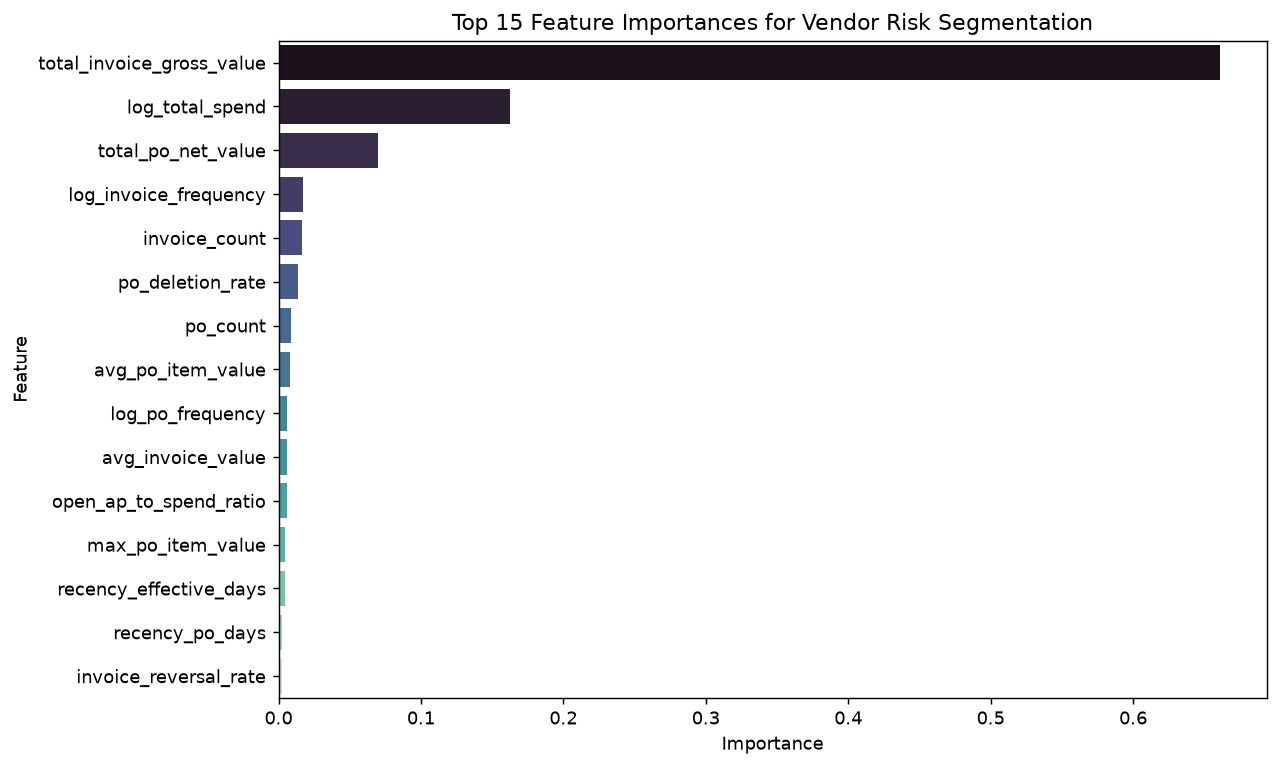

In [19]:
# 19. Feature Importance (All 32 Vendor Risk Segmentation Features)
surrogate = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
surrogate.fit(X_test_scaled, scores_km)

feat_imp = pd.DataFrame({
    'Feature': FEATURE_COLS,
    'Importance': surrogate.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp.head(15), x='Importance', y='Feature', palette='mako')
plt.title('Top 15 Feature Importances for Vendor Risk Segmentation')
plt.tight_layout()
plt.show()

print(feat_imp.head(15).to_string(index=False))


In [20]:
# 20. Final Vendor Risk Segmentation & Risk Triage using Selected #1 Champion Model
from src.models import SingleModelVendorRiskSegmenter
from src.inference import score_with_single_model

segmenter = SingleModelVendorRiskSegmenter(n_clusters=4, contamination=contamination_rate, random_state=42, pretrained_model=km_model)
segmenter.fit(X_train_scaled)
df_scored = score_with_single_model(df, segmenter, scaler, FEATURE_COLS)

print("=== VENDOR RISK SEGMENT COUNTS ===")
print(df_scored['vendor_segment_name'].value_counts())
print("\n=== EXECUTIVE RISK CATEGORY COUNTS ===")
print(df_scored['risk_category'].value_counts())

audit_cols = ['vendor_id', 'vendor_name', 'purchasing_org', 'vendor_tier_code', 'vendor_reliability_score', 'vendor_segment_name', 'vendor_risk_prob', 'risk_category']
print(df_scored[df_scored['risk_category'] == 'Critical Risk'][audit_cols].head(10).to_string(index=False))


[INFO] Fitting Selected #1 Champion Model: K-Means Clustering for Vendor Risk Segmentation...
[INFO] Champion K-Means fitted (4 Vendor Risk Segments). Risk Threshold: 0.9899
=== VENDOR RISK SEGMENT COUNTS ===
vendor_segment_name
Watchlist / Moderate-Risk Vendors              500962
High-Risk / Non-Compliant / Blocked Vendors    307286
Preferred / Core Operational Vendors           104367
Strategic / High-Reliability Vendors            10069
Name: count, dtype: int64

=== EXECUTIVE RISK CATEGORY COUNTS ===
risk_category
High Risk        645454
Critical Risk    162653
Low Risk          69716
Medium Risk       44861
Name: count, dtype: int64
vendor_id                        vendor_name purchasing_org vendor_tier_code  vendor_reliability_score                         vendor_segment_name  vendor_risk_prob risk_category
150000017 Western Bainoona Group for General           1000         D1-I2-Q2                     17.16 High-Risk / Non-Compliant / Blocked Vendors          0.960307 Critical 

In [21]:
# 21. Save Champion Model & Scaler
os.makedirs("models", exist_ok=True)

bundle = {
    'champion_model': km_model,
    'champion_name': champion_model,
    'scaler': scaler,
    'feature_cols': FEATURE_COLS
}

joblib.dump(bundle, "models/vendor_risk_model_bundle.joblib")
joblib.dump(scaler, "models/robust_scaler.joblib")
print("Saved champion clustering model bundle and scaler to models/")


Saved champion clustering model bundle and scaler to models/
